# Six Sigma DMAIC — Phase 1: Define (定义阶段)

> **数据源**: `SigmaFlow/templates/DMAIC_01_Define_Template.xlsx`
> **核心工具**: Project Charter (立项章程)、SIPOC (流程高阶图)、VOC to CTQ (客户心声转化矩阵)、Defect Pareto (缺陷帕累托分析图)
> **Minitab 替代实现**: 纯 Python 自动化读取 Excel 模板，分析输出的数据表均以 Minitab 风格图片（PNG）与图表同步输出。


In [1]:
# 1. 环境准备与模块加载
import sys
from pathlib import Path

PROJECT_ROOT = next((p for p in [Path.cwd(), Path.cwd() / "SigmaFlow", Path.cwd().parent] if (p / "minitab_dmaic_visuals.py").exists()), Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image

import importlib
import minitab_dmaic_visuals as mv
importlib.reload(mv)
mv.apply_minitab_theme()

TEMPLATE_PATH = PROJECT_ROOT / "templates" / "DMAIC_01_Define_Template.xlsx"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"Loading Define Template from: {TEMPLATE_PATH}")


Loading Define Template from: c:\Users\dmnandlu\DeskBox\文件夹\Black belt\capability-sixpack\SigmaFlow\templates\DMAIC_01_Define_Template.xlsx


## 1.1 项目立项章程 (Project Charter)
读取 Excel 模板的 `Project_Charter` 工作表，并以 Minitab 风格数据表图片输出。


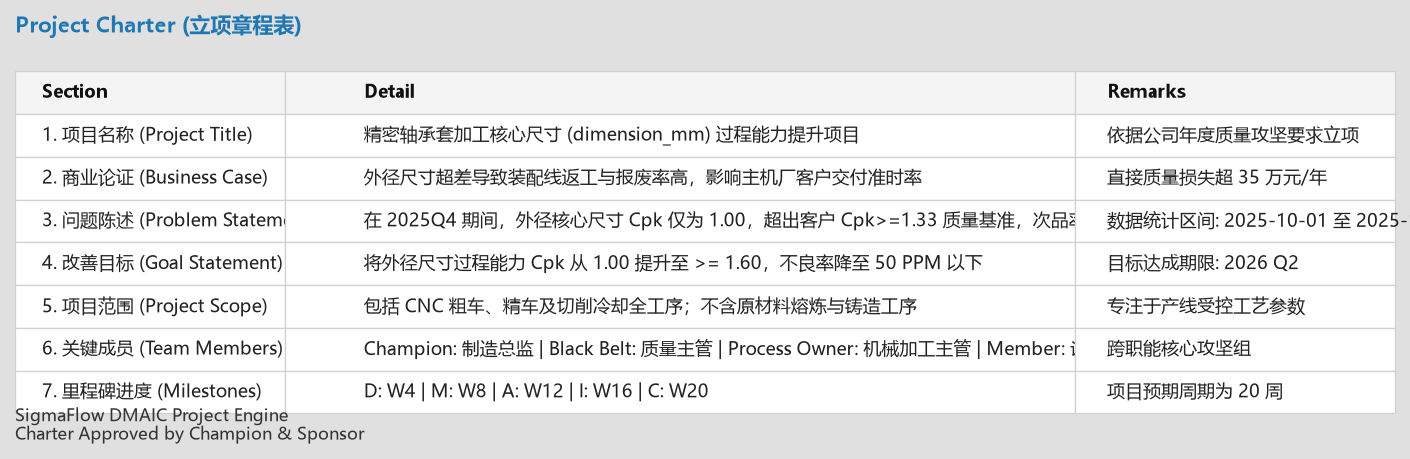

In [2]:
df_charter = pd.read_excel(TEMPLATE_PATH, sheet_name="Project_Charter")
out_charter_img = FIG_DIR / "phase1_project_charter_table.png"

mv.render_table_card(
    df_charter,
    title="Project Charter (立项章程表)",
    footer_lines=["SigmaFlow DMAIC Project Engine", "Charter Approved by Champion & Sponsor"],
    output_path=str(out_charter_img)
)
display(Image(filename=str(out_charter_img)))


## 1.2 高阶流程映射 (SIPOC Analysis)
读取 Excel 模板的 `SIPOC` 工作表，界定供应商、输入、5大核心工艺工序、输出及客户交付边界。


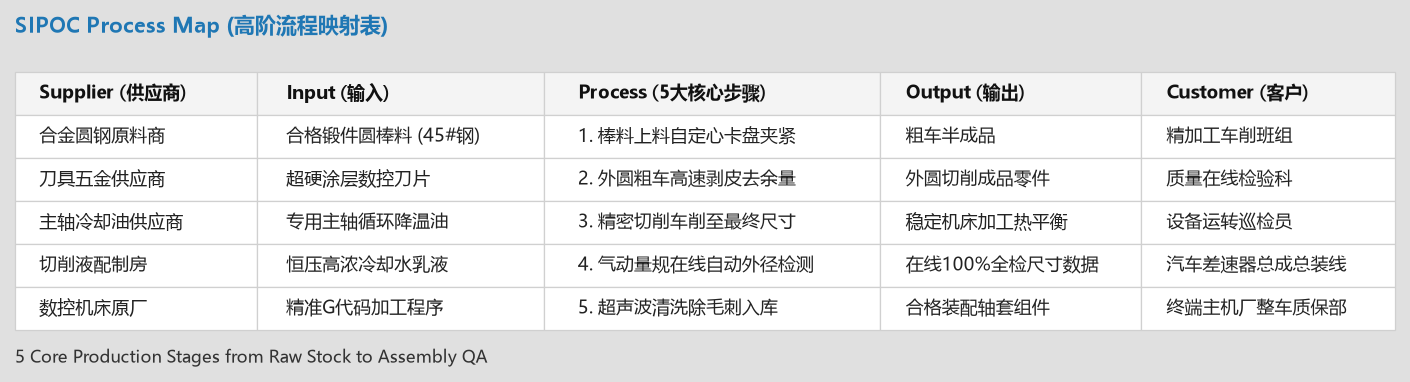

In [3]:
df_sipoc = pd.read_excel(TEMPLATE_PATH, sheet_name="SIPOC")
out_sipoc_img = FIG_DIR / "phase1_sipoc_table.png"

mv.render_table_card(
    df_sipoc,
    title="SIPOC Process Map (高阶流程映射表)",
    footer_lines=["5 Core Production Stages from Raw Stock to Assembly QA"],
    output_path=str(out_sipoc_img)
)
display(Image(filename=str(out_sipoc_img)))


## 1.3 客户声音转化为关键质量特性 (VOC to CTQ Matrix)
读取 Excel 模板的 `VOC_to_CTQ` 工作表，将定性客户抱怨转化为可量化工程规范。


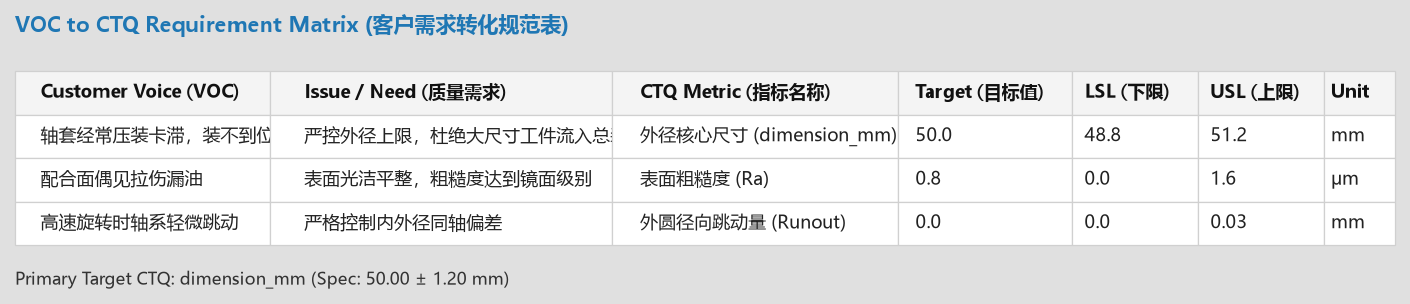

In [5]:
df_voc = pd.read_excel(TEMPLATE_PATH, sheet_name="VOC_to_CTQ")
out_voc_img = FIG_DIR / "phase1_voc_ctq_table.png"

mv.render_table_card(
    df_voc,
    title="VOC to CTQ Requirement Matrix (客户需求转化规范表)",
    footer_lines=["Primary Target CTQ: dimension_mm (Spec: 50.00 ± 1.20 mm)"],
    output_path=str(out_voc_img)
)
display(Image(filename=str(out_voc_img)))


## 1.4 CTQ 缺陷 Pareto 图与明细表分析 (Minitab 风格)
读取 Excel 模板的 `Defect_Pareto` 工作表，输出 Pareto 图及对应损失明细数据表图片。


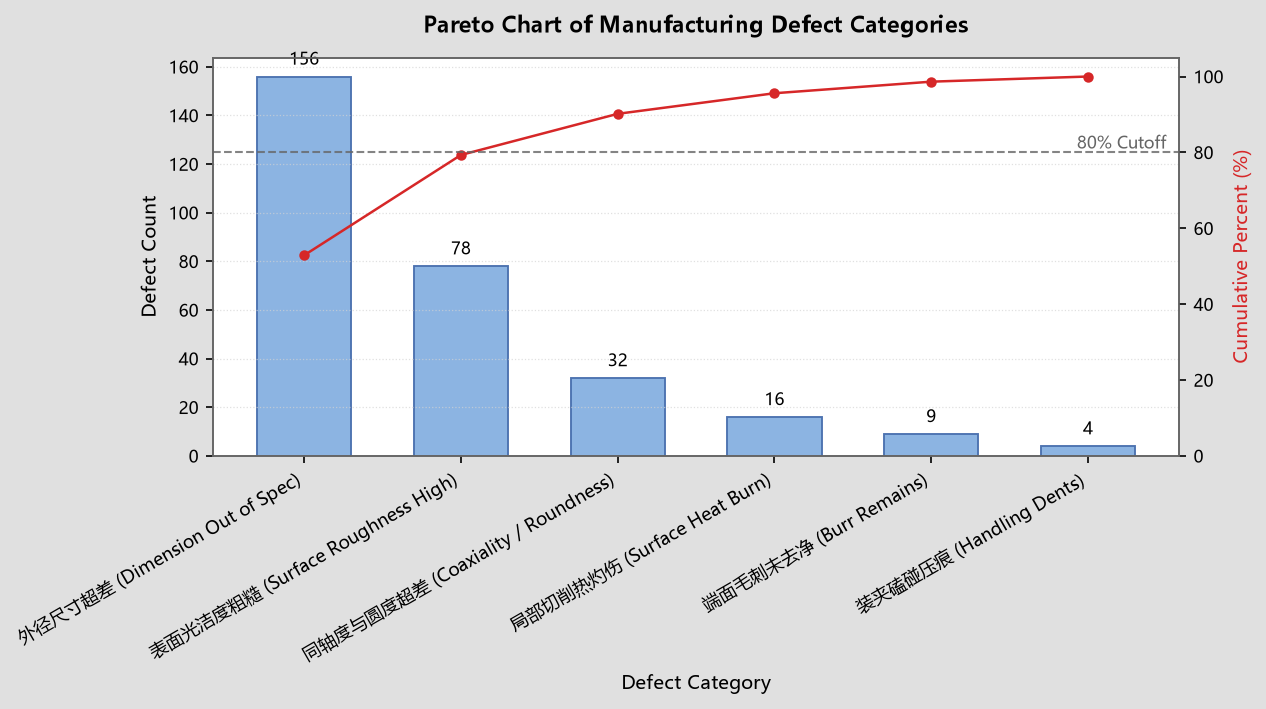

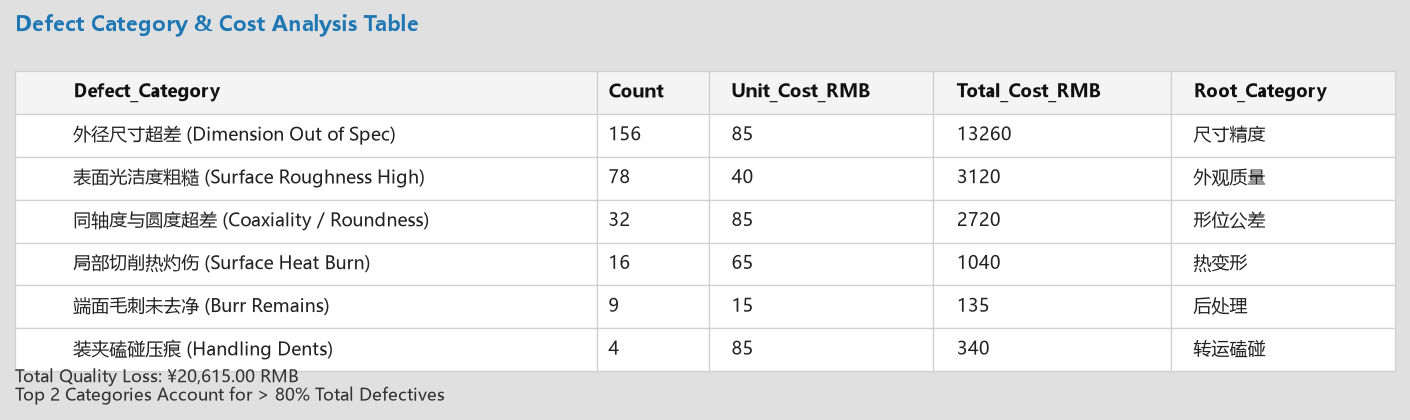

In [6]:
df_pareto = pd.read_excel(TEMPLATE_PATH, sheet_name="Defect_Pareto")
defect_series = df_pareto.set_index("Defect_Category")["Count"]

out_pareto_chart = FIG_DIR / "phase1_define_pareto.png"
out_pareto_table = FIG_DIR / "phase1_defect_pareto_table.png"

fig = mv.plot_pareto_chart(
    defect_series,
    title="Pareto Chart of Manufacturing Defect Categories",
    xlabel="Defect Category",
    ylabel="Defect Count",
    output_path=str(out_pareto_chart)
)

mv.render_table_card(
    df_pareto,
    title="Defect Category & Cost Analysis Table",
    footer_lines=[f"Total Quality Loss: ¥{df_pareto['Total_Cost_RMB'].sum():,.2f} RMB", "Top 2 Categories Account for > 80% Total Defectives"],
    output_path=str(out_pareto_table)
)

display(Image(filename=str(out_pareto_chart)))
display(Image(filename=str(out_pareto_table)))


### 📌 Define 阶段总结与交付物
1. **范围锁定**: 锁定外径核心尺寸 `dimension_mm`（规格目标 50.00 ± 1.20 mm）。
2. **数据表与图表图片化交付**:
   - `phase1_project_charter_table.png`
   - `phase1_sipoc_table.png`
   - `phase1_voc_ctq_table.png`
   - `phase1_define_pareto.png` & `phase1_defect_pareto_table.png`
